<a href="https://colab.research.google.com/github/adipelled/spotify-top10-predictor/blob/main/spotify_top10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import pandas as pd
df = pd.read_csv('/content/drive/MyDrive/Spotify-project/universal_top_spotify_songs.csv')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


Week 1:

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the shared file (use the exact file name in the shared Drive folder)
print(df.shape)
print(df.isna().sum())

# Drop the Global chart (blank country)
df = df.dropna(subset=["country"])

# Turn date text into real dates
df["snapshot_date"] = pd.to_datetime(df["snapshot_date"])
df["album_release_date"] = pd.to_datetime(df["album_release_date"], errors="coerce")

audio = ["danceability", "energy", "loudness", "speechiness", "acousticness",
         "instrumentalness", "liveness", "valence", "tempo"]

# Collapse to one row per song per country
songs = (df.groupby(["spotify_id", "country"])
           .agg(best_rank=("daily_rank", "min"),
                first_seen=("snapshot_date", "min"),
                release=("album_release_date", "first"),
                is_explicit=("is_explicit", "first"),
                duration_ms=("duration_ms", "first"),
                                danceability=("danceability", "first"),
                energy=("energy", "first"),
                loudness=("loudness", "first"),
                speechiness=("speechiness", "first"),
                acousticness=("acousticness", "first"),
                instrumentalness=("instrumentalness", "first"),
                liveness=("liveness", "first"),
                valence=("valence", "first"),
                tempo=("tempo", "first"))
           .reset_index())

# New features
songs["duration_min"] = songs["duration_ms"] / 60000
songs["days_since_release"] = (songs["first_seen"] - songs["release"]).dt.days.clip(lower=0)
songs["is_explicit"] = songs["is_explicit"].astype(int)

# Target: did the song ever reach rank 10 or better in that country?
songs["top_10"] = (songs["best_rank"] <= 10).astype(int)

# Drop rows missing any feature we will use
songs = songs.dropna(subset=audio + ["duration_min", "days_since_release"])

print(songs.shape)   # (rows, columns)

(2110316, 25)
spotify_id                0
name                     30
artists                  29
daily_rank                0
daily_movement            0
weekly_movement           0
country               28908
snapshot_date             0
popularity                0
is_explicit               0
duration_ms               0
album_name              822
album_release_date      659
danceability              0
energy                    0
key                       0
loudness                  0
mode                      0
speechiness               0
acousticness              0
instrumentalness          0
liveness                  0
valence                   0
tempo                     0
time_signature            0
dtype: int64
(53689, 19)


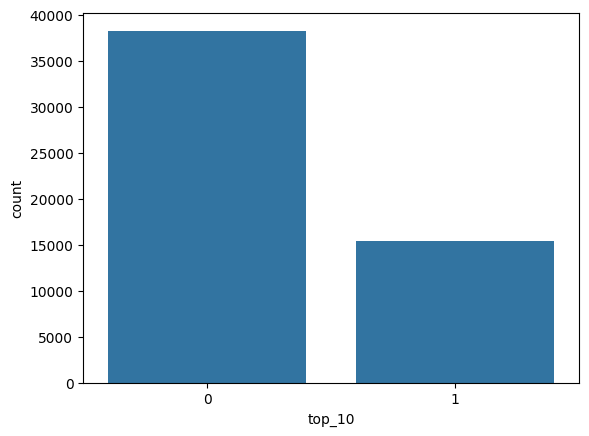

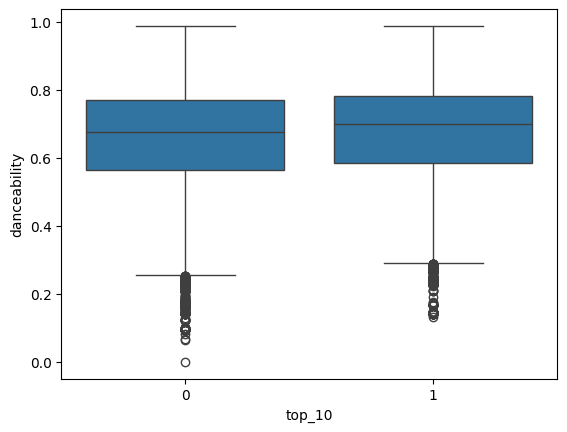

is_explicit
0    0.278
1    0.301
Name: top_10, dtype: float64


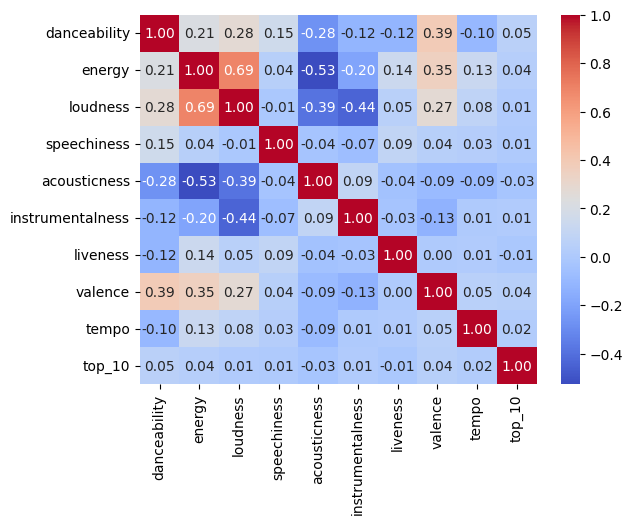

In [ ]:
# 1. How many songs are Top 10 vs. not?
sns.countplot(data=songs, x="top_10"); plt.show()

# 2. Danceability for Top 10 vs. not
sns.boxplot(data=songs, x="top_10", y="danceability"); plt.show()

# 3. Top 10 rate by explicit vs. not
print(songs.groupby("is_explicit")["top_10"].mean().round(3))

# 4. Correlation heatmap of the audio features
sns.heatmap(songs[audio + ["top_10"]].corr(), annot=True, fmt=".2f", cmap="coolwarm"); plt.show()


## Week 2

In [ ]:
from sklearn.model_selection import GroupShuffleSplit
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier

num_cols = audio + ["duration_min", "days_since_release", "is_explicit"] #from week1
cat_cols = ["country"]

X = songs[num_cols + cat_cols] #prediction
y = songs["top_10"] #output

# Split by song so the same song never appears in both train and test
# (each song has one row per country, and its audio features are identical across countries)
groups = songs["spotify_id"] #on id of the song
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42) #n_splits=1 makes one train/test split
train_idx, test_idx = next(gss.split(X, y, groups=groups)) #does the split and returns two lists of row positions, one for train and one for test (next is first split only)
X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
groups_train = groups.iloc[train_idx] #needed for grouped cross-validation in week 3

# A function so every model gets its own fresh copy of the prep steps [StandardScaler puts all number columns on the same scale.
# OneHotEncoder turns country into 0/1 columns, one per country, because models need numbers, not text.]
def make_prep():
    return ColumnTransformer([
        ("num", StandardScaler(), num_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols)])

logit = Pipeline([
    ("prep", make_prep()), #prep before the model
    ("model", LogisticRegression(max_iter=1000, class_weight="balanced"))])
logit.fit(X_train, y_train)
# max_iter=1000 caps how many iterations the solver gets to find the best coefficients

dummy = DummyClassifier(strategy="most_frequent")
#ignores the features and always guesses the most common answer, which is not Top 10
dummy.fit(X_train, y_train)

print("Dummy accuracy:", round(dummy.score(X_test, y_test), 3))
print("Logistic accuracy:", round(logit.score(X_test, y_test), 3))


Dummy accuracy: 0.706
Logistic accuracy: 0.557


## Week 3:

Dummy (always 'not Top 10'):
              precision    recall  f1-score   support

           0       0.71      1.00      0.83      7806
           1       0.00      0.00      0.00      3247

    accuracy                           0.71     11053
   macro avg       0.35      0.50      0.41     11053
weighted avg       0.50      0.71      0.58     11053

Logistic regression:
              precision    recall  f1-score   support

           0       0.76      0.54      0.63      7806
           1       0.35      0.59      0.44      3247

    accuracy                           0.56     11053
   macro avg       0.56      0.57      0.54     11053
weighted avg       0.64      0.56      0.58     11053



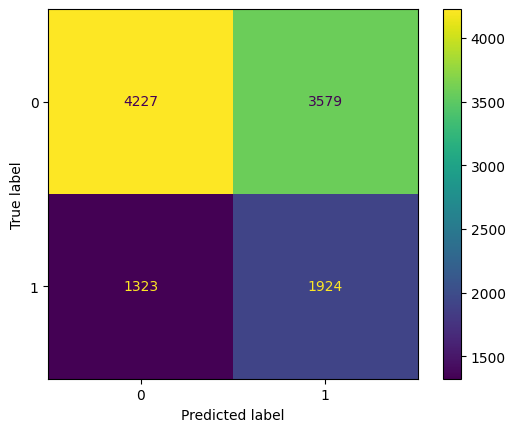

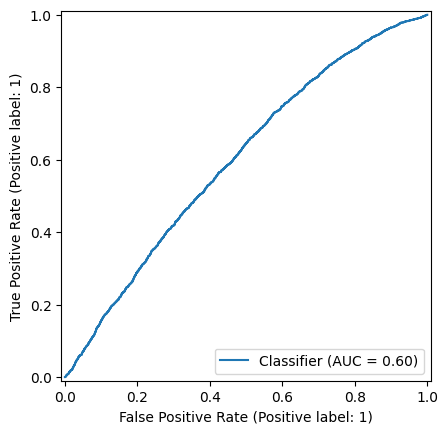

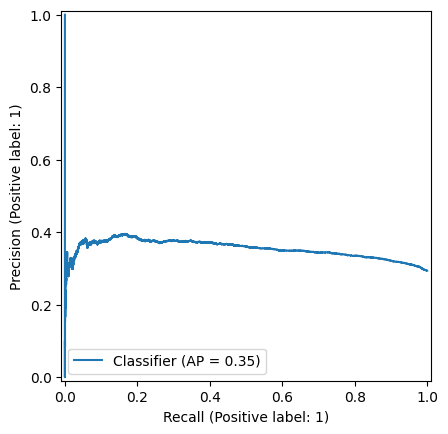

CV ROC-AUC by fold: [0.575 0.553 0.56  0.563 0.586]
F1: 0.44
ROC-AUC: 0.599
Avg precision: 0.354 | baseline (Top 10 rate): 0.294
CV mean: 0.567 CV std: 0.012


In [ ]:
from sklearn.metrics import (classification_report, roc_auc_score, f1_score,
                             average_precision_score, ConfusionMatrixDisplay,
                             RocCurveDisplay, PrecisionRecallDisplay)
from sklearn.model_selection import StratifiedGroupKFold, cross_val_score

y_pred = logit.predict(X_test)
y_prob = logit.predict_proba(X_test)[:, 1]   # probability of Top 10, from week 2

# Baseline vs. logistic regression
print("Dummy (always 'not Top 10'):")
print(classification_report(y_test, dummy.predict(X_test), zero_division=0))
print("Logistic regression:")
print(classification_report(y_test, y_pred))

ConfusionMatrixDisplay.from_predictions(y_test, y_pred); plt.show()
RocCurveDisplay.from_predictions(y_test, y_prob); plt.show()
PrecisionRecallDisplay.from_predictions(y_test, y_prob); plt.show()

# 5-fold cross-validation on the training data, keeping each song in a single fold
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
cv_scores = cross_val_score(logit, X_train, y_train, cv=cv,
                            scoring="roc_auc", groups=groups_train)
print("CV ROC-AUC by fold:", cv_scores.round(3))

# checking
print("F1:", round(f1_score(y_test, y_pred), 3))
print("ROC-AUC:", round(roc_auc_score(y_test, y_prob), 3))
print("Avg precision:", round(average_precision_score(y_test, y_prob), 3),
      "| baseline (Top 10 rate):", round(y_test.mean(), 3))
print("CV mean:", cv_scores.mean().round(3), "CV std:", cv_scores.std().round(3))

# ROC-AUC: 0.5 = random guessing, 1.0 = perfect
# Avg precision: compare to the Top 10 rate (0.294); higher means better than random ranking

ROC-AUC: 0.599 on the test set, 0.567 in CV.

0.5 is random guessing, so the model is better than chance, but not by much.
The test score is a bit higher than the CV mean: 0.599 − 0.567 = 0.032. The CV std is 0.012, and 0.032 ÷ 0.012 ≈ 2.7 standard deviations, so the test split was probably a slightly favorable draw. The more trustworthy number is 0.567.
The folds range from 0.553 to 0.586, a spread of 0.586 − 0.553 = 0.033. That’s tight, so the result is stable rather than a fluke.

Average precision: 0.354 vs. a baseline of 0.294.

0.354 − 0.294 = 0.060 above random.
0.354 ÷ 0.294 ≈ 1.20, so the model ranks songs about 20% better than chance.

Song features like danceability and energy help a little in predicting a top 10 hit, but not much. Things like artist popularity and marketing probably matter more.

## Week 4

(42636, 13)
                   model  test_f1  test_roc_auc
0    Logistic regression    0.440         0.599
1  Random forest (tuned)    0.454         0.647


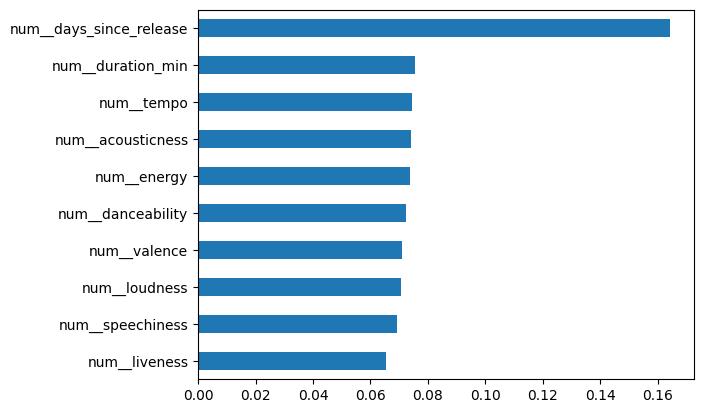

{'model__n_estimators': 200, 'model__min_samples_leaf': 1, 'model__max_depth': 15}
0.611
                   model  test_f1  test_roc_auc
0    Logistic regression    0.440         0.599
1  Random forest (tuned)    0.454         0.647


In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RandomizedSearchCV, StratifiedGroupKFold

print(X_train.shape)   # how many training songs and columns

rf = Pipeline([
    ("prep", make_prep()),   # same prep as week 2
    ("model", RandomForestClassifier(random_state=42, class_weight="balanced"))])

# Knob settings to choose from: 2 x 3 x 3 = 18 combinations
params = {
    "model__n_estimators": [100, 200],      # how many trees vote
    "model__max_depth": [5, 10, 15],        # how many questions each tree can ask
    "model__min_samples_leaf": [1, 5, 10]}  # how many songs each final answer must cover

# 3-fold CV, keeping each song in a single fold
cv3 = StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=42)

# Try 6 of the 18 combinations, score each with CV, keep the best
search = RandomizedSearchCV(rf, params, n_iter=6, cv=cv3, scoring="roc_auc",
                            random_state=42, n_jobs=-1)
search.fit(X_train, y_train, groups=groups_train)   # takes a few minutes

#comparison and feature importance:
best = search.best_estimator_   # the whole pipeline: prep + tuned forest
rf_prob = best.predict_proba(X_test)[:, 1]   # probability of Top 10 for each test song

# Comparison table on the test songs
results = pd.DataFrame({
    "model": ["Logistic regression", "Random forest (tuned)"],
    "test_f1": [f1_score(y_test, y_pred), f1_score(y_test, best.predict(X_test))],
    "test_roc_auc": [roc_auc_score(y_test, y_prob), roc_auc_score(y_test, rf_prob)]}).round(3)
print(results)

# Top 10 most important features
names = best.named_steps["prep"].get_feature_names_out()
imp = pd.Series(best.named_steps["model"].feature_importances_, index=names)
imp.sort_values().tail(10).plot(kind="barh"); plt.show()

print(search.best_params_)            # the winning settings
print(round(search.best_score_, 3))   # average CV ROC-AUC of the winner
print(results)

The tuned random forest beat logistic regression on test ROC-AUC, 0.647 vs. 0.599, so it ranks songs substantially better, even though their F1 scores are close (0.454 vs. 0.440). The winning settings were the most complex ones we offered: 200 trees, depth 15, and leaf size 1. The CV score (0.611) came out lower than the test score, but that’s because each CV fold trained on less data, not because something went wrong. Since we split by song, these scores are honest: the model is predicting songs it has never seen, and the forest becomes our team model for week 5.

## Week 5 Code

In [ ]:
import joblib
joblib.dump(best, "/content/drive/MyDrive/Spotify-project/top10_model.joblib")
print("Saved")

!pip install gradio

from google.colab import drive
drive.mount("/content/drive")

import gradio as gr
import joblib
import pandas as pd

model = joblib.load("/content/drive/MyDrive/Spotify-project/top10_model.joblib")
countries = sorted(songs["country"].unique())

# Typical (median) value of every audio feature, used for the ones without a slider
typical = songs[audio].median()

def predict(country, danceability, energy, valence, tempo, duration_min, days, explicit):
    # One row with every column the model trained on
    song = pd.DataFrame([{
        **typical.to_dict(),                          # start from a typical song
        "danceability": danceability, "energy": energy,
        "valence": valence, "tempo": tempo,           # overwrite with the slider values
        "duration_min": duration_min,
        "days_since_release": max(int(days), 0),      # no negative days, same as week 1
        "is_explicit": int(explicit),
        "country": country}])
    score = model.predict_proba(song)[0, 1]
    return f"Top 10 score: {score:.2f} (higher = more hit-like, not a true probability)"

inputs = [
    gr.Dropdown(countries, value=countries[0], label="Country"),
    gr.Slider(0, 1, 0.75, label="Danceability"),
    gr.Slider(0, 1, 0.65, label="Energy"),
    gr.Slider(0, 1, 0.5, label="Valence (how happy it sounds)"),
    gr.Slider(60, 200, 120, label="Tempo (BPM)"),
    gr.Slider(1.5, 6, 3.2, label="Length (minutes)"),
    gr.Number(14, label="Days since release", minimum=0),
    gr.Checkbox(label="Explicit")]

app = gr.Interface(fn=predict, inputs=inputs, outputs=gr.Textbox(label="Prediction"),
                   title="Will it crack the Top 10?",
                   description="Set a song's features and see how hit-like the model thinks it is. "
                               "Features without a slider are set to a typical song's value. "
                               "Our model is only modestly better than guessing, so expect small changes.")
app.launch(share=True)

Saved
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://defff7ed615615d700.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
